# Chi-square (χ²) testing in genetics

This notebook reproduces the worked examples from Chapter 11 of the lab manual
(*Mendelian Genetics in Corn and Chi-Square Testing*) in R, and applies the same
test to a human genetics data set. It uses base R only (no extra packages).

In [1]:
# Plot size for slides
options(repr.plot.width = 8, repr.plot.height = 4.5, repr.plot.res = 120)

## 1. Monohybrid cross: expected 3:1 ratio

In [2]:
observed <- c(Tall = 78, Short = 22)
ratio    <- c(3, 1)
expected <- sum(observed) * ratio / sum(ratio)
data.frame(observed, expected = round(expected, 1),
           contribution = round((observed - expected)^2 / expected, 3))

,observed,expected,contribution
,<dbl>,<dbl>,<dbl>
Tall,78,75,0.12
Short,22,25,0.36


In [3]:
chisq.test(observed, p = ratio / sum(ratio))


	Chi-squared test for given probabilities

data:  observed
X-squared = 0.48, df = 1, p-value = 0.4884


## 2. Dihybrid cross: expected 9:3:3:1 ratio

In [4]:
observed <- c(`Round yellow` = 190, `Round green` = 65,
              `Wrinkled yellow` = 40, `Wrinkled green` = 25)
ratio    <- c(9, 3, 3, 1)
expected <- sum(observed) * ratio / sum(ratio)
contribution <- (observed - expected)^2 / expected
data.frame(observed, expected, contribution = round(contribution, 3))

,observed,expected,contribution
,<dbl>,<dbl>,<dbl>
Round yellow,190,180,0.556
Round green,65,60,0.417
Wrinkled yellow,40,60,6.667
Wrinkled green,25,20,1.250


In [5]:
di_result <- chisq.test(observed, p = ratio / sum(ratio))
di_result


	Chi-squared test for given probabilities

data:  observed
X-squared = 8.8889, df = 3, p-value = 0.03081


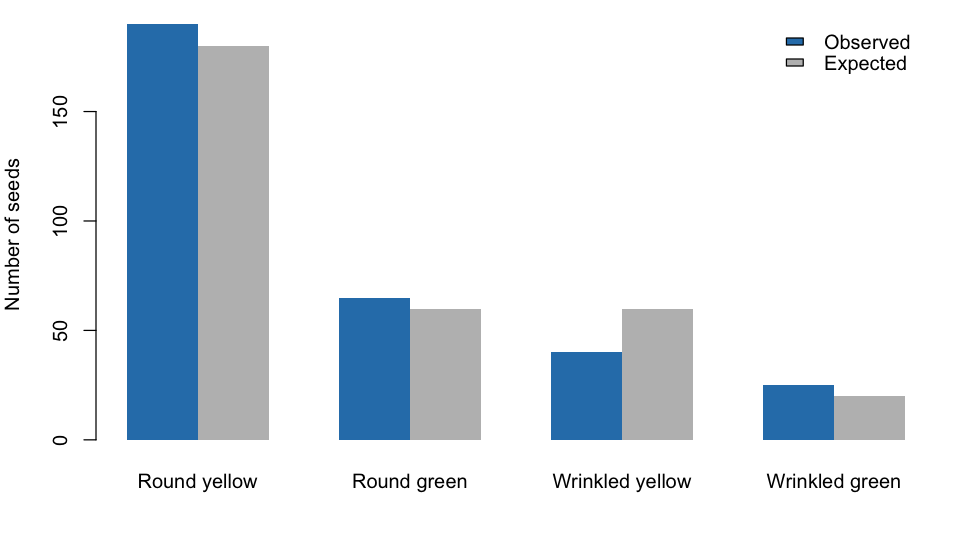

In [6]:
par(mar = c(4, 4, 1, 1))
barplot(rbind(Observed = observed, Expected = expected), beside = TRUE,
        col = c("#2c7fb8", "#bdbdbd"), border = NA, ylab = "Number of seeds",
        legend.text = TRUE, args.legend = list(x = "topright", bty = "n", y.intersp = 1.5))

## 3. Critical values and the χ² distribution

In [7]:
data.frame(df = 1:4, critical_value = round(qchisq(0.95, df = 1:4), 2))

df,critical_value
<int>,<dbl>
1,3.84
2,5.99
3,7.81
4,9.49


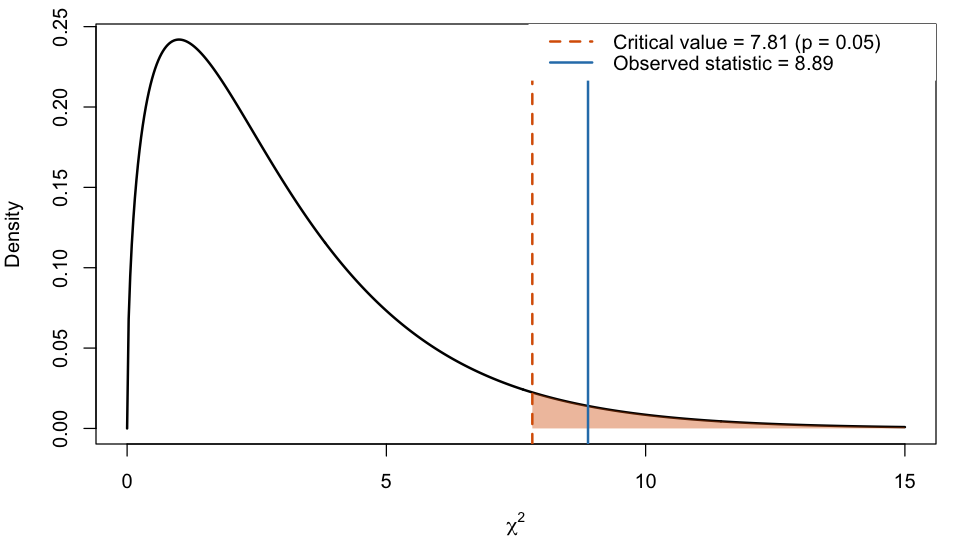

In [8]:
stat <- unname(di_result$statistic)
crit <- qchisq(0.95, df = 3)
x <- seq(0, 15, length.out = 500)
par(mar = c(4, 4, 1, 1))
plot(x, dchisq(x, df = 3), type = "l", lwd = 2,
     xlab = expression(chi^2), ylab = "Density")
tail_x <- x[x >= crit]
polygon(c(crit, tail_x, max(x)), c(0, dchisq(tail_x, df = 3), 0),
        col = adjustcolor("#d95f02", 0.4), border = NA)
abline(v = crit, lty = 2, lwd = 2, col = "#d95f02")
abline(v = stat, lwd = 2, col = "#2c7fb8")
legend("topright", bg = "white", box.col = "white", y.intersp = 1.5, lty = c(2, 1), lwd = 2, col = c("#d95f02", "#2c7fb8"),
       legend = c(sprintf("Critical value = %.2f (p = 0.05)", crit),
                  sprintf("Observed statistic = %.2f", stat)))

## 4. Human genetics: MN blood group and Hardy–Weinberg equilibrium

Genotype counts for 1,279 people in England (Race & Sanger, 1975).
The M and N alleles are codominant, so every genotype can be counted directly.

In [9]:
observed <- c(MM = 363, MN = 634, NN = 282)
n <- sum(observed)
p <- unname((2 * observed["MM"] + observed["MN"]) / (2 * n))  # frequency of M
q <- 1 - p                                                     # frequency of N
expected <- n * c(MM = p^2, MN = 2 * p * q, NN = q^2)
round(c(p = p, q = q), 4)
data.frame(observed, expected = round(expected, 1),
           contribution = round((observed - expected)^2 / expected, 3))

p      q 
0.5317 0.4683

,observed,expected,contribution
,<dbl>,<dbl>,<dbl>
MM,363,361.5,0.006
MN,634,636.9,0.014
NN,282,280.5,0.008


In [10]:
# df = 3 genotypes - 1 - 1 allele frequency estimated from the data = 1
stat <- sum((observed - expected)^2 / expected)
round(c(chi_square = stat, df = 1,
        p_value = pchisq(stat, df = 1, lower.tail = FALSE)), 3)

chi_square         df    p_value 
     0.027      1.000      0.869